# Correction — Gradient descent

La correction compare le gradient analytique à une différence finie, puis étudie deux learning rates sur les trois mêmes points. L'objectif est de lire la trajectoire d'optimisation, pas seulement le dernier coefficient.

## Relier formule et variables

Pour `prediction = w*x+b`, `error = prediction-y`. La dérivée de la MSE selon `w` est `2*mean(error*x)` ; celle de `b` est `2*mean(error)`. La différence finie centrée est une vérification indépendante locale. Elle peut devenir imprécise si `epsilon` est trop petit à cause des arrondis.

In [ ]:
import numpy as np
x = np.array([1.0, 2.0, 3.0]); y = 2 * x - 1
print('dot product:', x @ np.array([0.2, 0.3, 0.5]))
def loss(w, b): return np.mean((w * x + b - y) ** 2)
epsilon = 1e-5; w, b = 0.4, 0.2
finite_difference = (loss(w + epsilon, b) - loss(w - epsilon, b)) / (2 * epsilon)
analytic = 2 * np.mean((w * x + b - y) * x)
print('finite difference / analytic:', finite_difference, analytic)
for rate in [0.01, 0.15]:
    w, b = 0.0, 0.0
    for _ in range(120):
        error = w * x + b - y
        w -= rate * 2 * np.mean(error * x); b -= rate * 2 * np.mean(error)
    print(rate, w, b, loss(w, b))


## Visualiser la convergence

La courbe montre la loss calculée avant chaque mise à jour. Le taux le plus élevé peut descendre plus vite ou osciller selon la courbure ; une comparaison est valable ici seulement parce que les deux essais utilisent les mêmes points et initialisations.

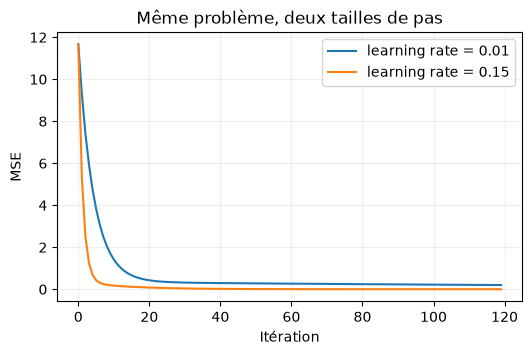

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6, 3.5))
for rate in [0.01, 0.15]:
    current_w, current_b = 0.0, 0.0
    history = []
    for _ in range(120):
        history.append(float(loss(current_w, current_b)))
        current_error = current_w * x + current_b - y
        next_w = current_w - rate * 2 * np.mean(current_error * x)
        next_b = current_b - rate * 2 * np.mean(current_error)
        current_w, current_b = next_w, next_b
    ax.plot(history, label=f'learning rate = {rate}')
ax.set(xlabel='Itération', ylabel='MSE', title='Même problème, deux tailles de pas')
ax.legend(); ax.grid(alpha=0.2)
plt.show()

## Interprétation et limite

Les deux méthodes de dérivation doivent donner des valeurs proches au point vérifié. Un pas qui fait baisser la loss sur ces données ne prouve pas une bonne prédiction sur de nouvelles observations. Avec plusieurs variables, leur échelle modifie la forme de la surface de perte et le pas utile.